# 07 — Model Evaluation

**Sections**
1. Setup & load
2. Reconstruct predictions
3. Overall metrics (Val / Test)
4. Per-station metrics
5. Residual analysis
6. Daily SSR
7. Prediction vs actual — top stations
8. Error breakdown by weekday / month

## 1. Setup & load

In [242]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from dotenv import load_dotenv
from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, np.nan, y_true))) * 100

def smape(y_true, y_pred):
    return np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred))) * 100

def mase(y_true, y_pred, y_train):
    naive_mae = np.mean(np.abs(np.diff(y_train)))
    return mean_absolute_error(y_true, y_pred) / naive_mae

def metrics_dict(y_true, y_pred, y_tr):
    return {
        'RMSE':  mean_squared_error(y_true, y_pred) ** 0.5,
        'MAE':   mean_absolute_error(y_true, y_pred),
        'MAPE':  mape(y_true.values, y_pred),
        'sMAPE': smape(y_true.values, y_pred),
        'MASE':  mase(y_true.values, y_pred, y_tr.values),
        'R2':    r2_score(y_true, y_pred),
    }

In [243]:
# Load model + metadata
MODEL_DIR  = '../models'
model = XGBRegressor()
model.load_model(os.path.join(MODEL_DIR, 'xgb_station_1day.json'))

with open(os.path.join(MODEL_DIR, 'xgb_station_1day_meta.json')) as f:
    meta = json.load(f)

FEATURES     = meta['features']
TARGET       = meta['target']
val_start    = pd.Timestamp(meta['val_start'])
test_start   = pd.Timestamp(meta['test_start'])

print(f'Features: {len(FEATURES)}')
print(f'Val start:  {val_start.date()}')
print(f'Test start: {test_start.date()}')

Features: 339
Val start:  2024-02-29
Test start: 2025-03-01


In [244]:
# Load & prepare data (same pipeline as training notebook)
station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
station = station[station['start_station_name'] != 'Outside of Dock']

weather      = s3.read_processed('weather/historical')
weather['date'] = pd.to_datetime(weather['date'])
weather_fcst = s3.read_processed('weather/forecast')
weather_fcst['date'] = pd.to_datetime(weather_fcst['date'])

n_days = station['date'].nunique()
min_active_days = int(0.95 * n_days)
active_stations = (
    station.groupby('start_station_name')['date']
    .nunique().loc[lambda s: s > min_active_days].index
)
df = station[station['start_station_name'].isin(active_stations)].copy()
df = df.merge(weather[['date','temp_min_c','rain_sum_mm','snowfall_sum_cm','wind_speed_max_kmh']], on='date', how='left')
df = df.sort_values(['start_station_name','date']).reset_index(drop=True)

df['day']          = df['date'].dt.day
df['month']        = df['date'].dt.month
df['weekday']      = df['date'].dt.weekday
for d in range(7):
    df[f'dow_{d}'] = (df['weekday'] == d).astype(int)
df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)
df['is_weekend']   = df['weekday'].isin([5,6]).astype(int)

grp = df.groupby('start_station_name')['total_rides']
for lag in [1, 2, 7, 30, 60, 90, 365]:
    df[f'y_lag{lag}'] = grp.shift(lag)

df['rolling_avg_7']  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=1).mean())
df['rolling_avg_30'] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=1).mean())
df['rolling_std_7']  = grp.shift(1).transform(lambda x: x.rolling(7,  min_periods=2).std())
df['rolling_std_30'] = grp.shift(1).transform(lambda x: x.rolling(30, min_periods=2).std())

total_safe = df['total_rides'].replace(0, np.nan)
df['ebike_prop']  = df['ebike_rides']  / total_safe
df['member_prop'] = df['member_rides'] / total_safe
for col in ['ebike_prop','member_prop']:
    df[f'{col}_roll365_lag1'] = (
        df.groupby('start_station_name')[col]
        .transform(lambda x: x.shift(1).rolling(365, min_periods=30).mean())
    )

station_dummies = pd.get_dummies(df['start_station_name'], prefix='stn', drop_first=False)
df = pd.concat([df, station_dummies], axis=1)
df = df.dropna(subset=['y_lag1', 'y_lag7', 'y_lag365'])
print(f'Rows: {len(df)}')


Rows: 575733


In [245]:
train = df[df['date'] <  val_start].copy()
val   = df[(df['date'] >= val_start) & (df['date'] < test_start)].copy()
test  = df[df['date'] >= test_start].copy()

WEATHER_COLS = ['temp_min_c','rain_sum_mm','snowfall_sum_cm','wind_speed_max_kmh']
test = test.drop(columns=WEATHER_COLS).merge(
    weather_fcst[['date'] + WEATHER_COLS], on='date', how='left'
)

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

y_pred_train = model.predict(X_train)
y_pred_val   = model.predict(X_val)
y_pred_test  = model.predict(X_test)

print('Predictions generated.')

Predictions generated.


## 2. Reconstruct predictions to original scale

In [246]:
# Predictions are already in original scale — just clip negatives
def build_eval(split_df, preds):
    out = split_df[['date','start_station_name','total_rides']].copy()
    out['pred']  = np.maximum(preds, 0)
    out['resid'] = out['total_rides'] - out['pred']
    return out

train_eval = build_eval(train, y_pred_train)
val_eval   = build_eval(val,   y_pred_val)
test_eval  = build_eval(test,  y_pred_test)
print('Eval dataframes built.')


Eval dataframes built.


## 3. Overall metrics

In [247]:
pd.DataFrame({
    'Train': metrics_dict(y_train, y_pred_train, y_train),
    'Val':   metrics_dict(y_val,   y_pred_val,   y_train),
    'Test':  metrics_dict(y_test,  y_pred_test,  y_train),
}).T.round(4)


,RMSE,MAE,MAPE,sMAPE,MASE,R2
Train,5.5705,3.9863,25.1917,20.3457,0.3656,0.9729
Val,11.1108,7.1215,41.9327,29.3170,0.6531,0.8687
Test,10.5769,6.7781,49.5507,31.4433,0.6217,0.8578


=== Original-scale metrics (all stations pooled) ===


,RMSE,MAE,sMAPE,R2
Train,5.570,3.986,20.346,0.973
Val,11.111,7.121,29.317,0.869
Test,10.577,6.778,31.443,0.858



=== Per-station R2 distribution (val) ===
count    311.000
mean       0.710
std        0.094
min        0.255
25%        0.658
50%        0.732
75%        0.778
max        0.856


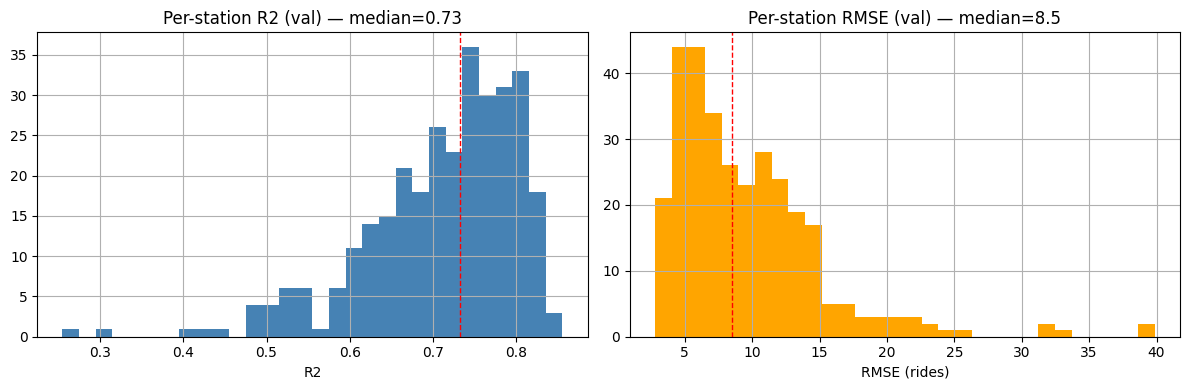


Bottom 10 stations by R2:


,R2,RMSE,MAE,n
start_station_name,,,,
Harper Ave & 59th St,0.255,3.728,2.893,357.0
Paulina St & Howard St,0.298,3.172,2.506,351.0
Clark St & Lunt Ave,0.400,4.593,3.544,362.0
Western Ave & Roscoe St,0.420,3.621,2.678,355.0
Washtenaw Ave & Lawrence Ave,0.450,3.166,2.485,352.0
Chicago Ave & Washington St,0.475,3.285,2.496,340.0
Racine Ave & Randolph St,0.491,4.611,3.597,352.0
Ashland Ave & 13th St,0.492,4.061,3.025,360.0
Clark St & Columbia Ave,0.493,2.779,2.155,364.0


In [248]:
def _stn_metrics(g):
    g = g[["total_rides","pred"]].dropna()
    if len(g) < 2:
        return {"R2": np.nan, "RMSE": np.nan, "MAE": np.nan, "n": len(g)}
    return {
        "R2":   r2_score(g["total_rides"], g["pred"]),
        "RMSE": mean_squared_error(g["total_rides"], g["pred"]) ** 0.5,
        "MAE":  mean_absolute_error(g["total_rides"], g["pred"]),
        "n":    len(g),
    }

def metrics_orig(df):
    tmp = df[["total_rides","pred"]].dropna()
    y_true, y_pred = tmp["total_rides"], tmp["pred"]
    return {
        "RMSE":  mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE":   mean_absolute_error(y_true, y_pred),
        "sMAPE": smape(y_true.values, y_pred.values),
        "R2":    r2_score(y_true, y_pred),
    }

orig_metrics = pd.DataFrame({
    "Train": metrics_orig(train_eval),
    "Val":   metrics_orig(val_eval),
    "Test":  metrics_orig(test_eval),
}).T.round(3)

print("=== Original-scale metrics (all stations pooled) ===")
display(orig_metrics)

per_stn = (
    val_eval.groupby("start_station_name")
    .apply(lambda g: pd.Series(_stn_metrics(g)))
    .sort_values("R2")
)

print("\n=== Per-station R2 distribution (val) ===")
print(per_stn["R2"].describe().round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
per_stn["R2"].hist(bins=30, ax=axes[0], color="steelblue", edgecolor="none")
axes[0].axvline(per_stn["R2"].median(), color="red", linestyle="--", linewidth=1)
axes[0].set_title("Per-station R2 (val) — median={:.2f}".format(per_stn["R2"].median()))
axes[0].set_xlabel("R2")
per_stn["RMSE"].hist(bins=30, ax=axes[1], color="orange", edgecolor="none")
axes[1].axvline(per_stn["RMSE"].median(), color="red", linestyle="--", linewidth=1)
axes[1].set_title("Per-station RMSE (val) — median={:.1f}".format(per_stn["RMSE"].median()))
axes[1].set_xlabel("RMSE (rides)")
plt.tight_layout()
plt.show()

print("\nBottom 10 stations by R2:")
display(per_stn.head(10).round(3))


## 4. Per-station metrics

Median R2: 0.7323  |  Stations R2>0.5: 302


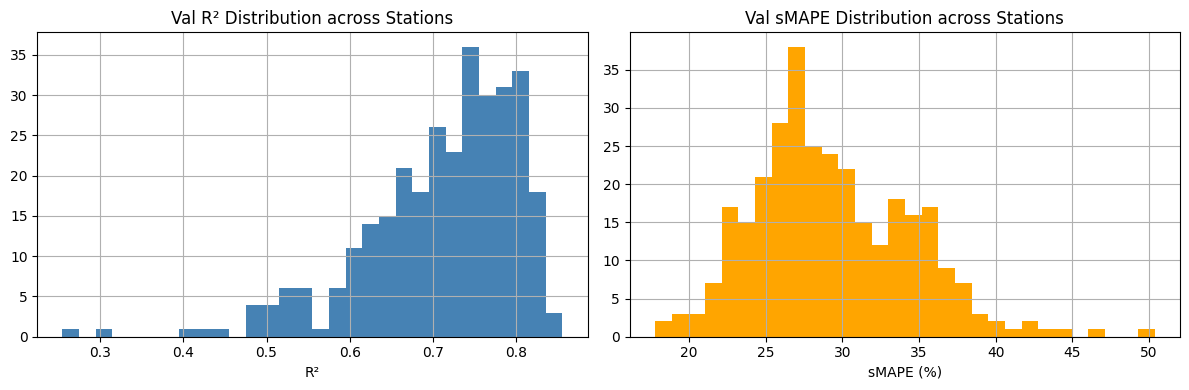

,rmse,mae,smape,r2
start_station_name,,,,
Michigan Ave & Oak St,38.971594,25.742039,37.139713,0.855729
Clark St & Elm St,19.220304,14.272320,17.779981,0.848157
Clark St & Lincoln Ave,21.812493,15.410317,30.438152,0.845313
Wells St & Huron St,14.480649,10.793372,19.486907,0.832069
LaSalle St & Illinois St,15.099515,11.195924,20.619757,0.831303
Lakeview Ave & Fullerton Pkwy,14.417979,10.334746,26.908479,0.829381
Wells St & Concord Ln,21.666623,15.854215,22.498079,0.828660
Wabash Ave & Grand Ave,17.210664,12.810556,21.443425,0.827672
Wells St & Evergreen Ave,12.445728,9.396086,24.692433,0.825152


In [249]:
per_station = (
    val_eval.groupby('start_station_name')
    .apply(lambda g: pd.Series({
        'rmse':  mean_squared_error(g[TARGET], g['pred']) ** 0.5,
        'mae':   mean_absolute_error(g[TARGET], g['pred']),
        'smape': smape(g[TARGET].values, g['pred'].values),
        'r2':    r2_score(g[TARGET], g['pred']),
    }))
    .sort_values('r2', ascending=False)
)
print(f'Median R2: {per_station["r2"].median():.4f}  |  Stations R2>0.5: {(per_station["r2"]>0.5).sum()}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
per_station['r2'].hist(bins=30, ax=axes[0], color='steelblue', edgecolor='none')
axes[0].set_title('Val R² Distribution across Stations')
axes[0].set_xlabel('R²')
per_station['smape'].hist(bins=30, ax=axes[1], color='orange', edgecolor='none')
axes[1].set_title('Val sMAPE Distribution across Stations')
axes[1].set_xlabel('sMAPE (%)')
plt.tight_layout()
plt.show()
per_station.head(10)

## 5. Residual analysis

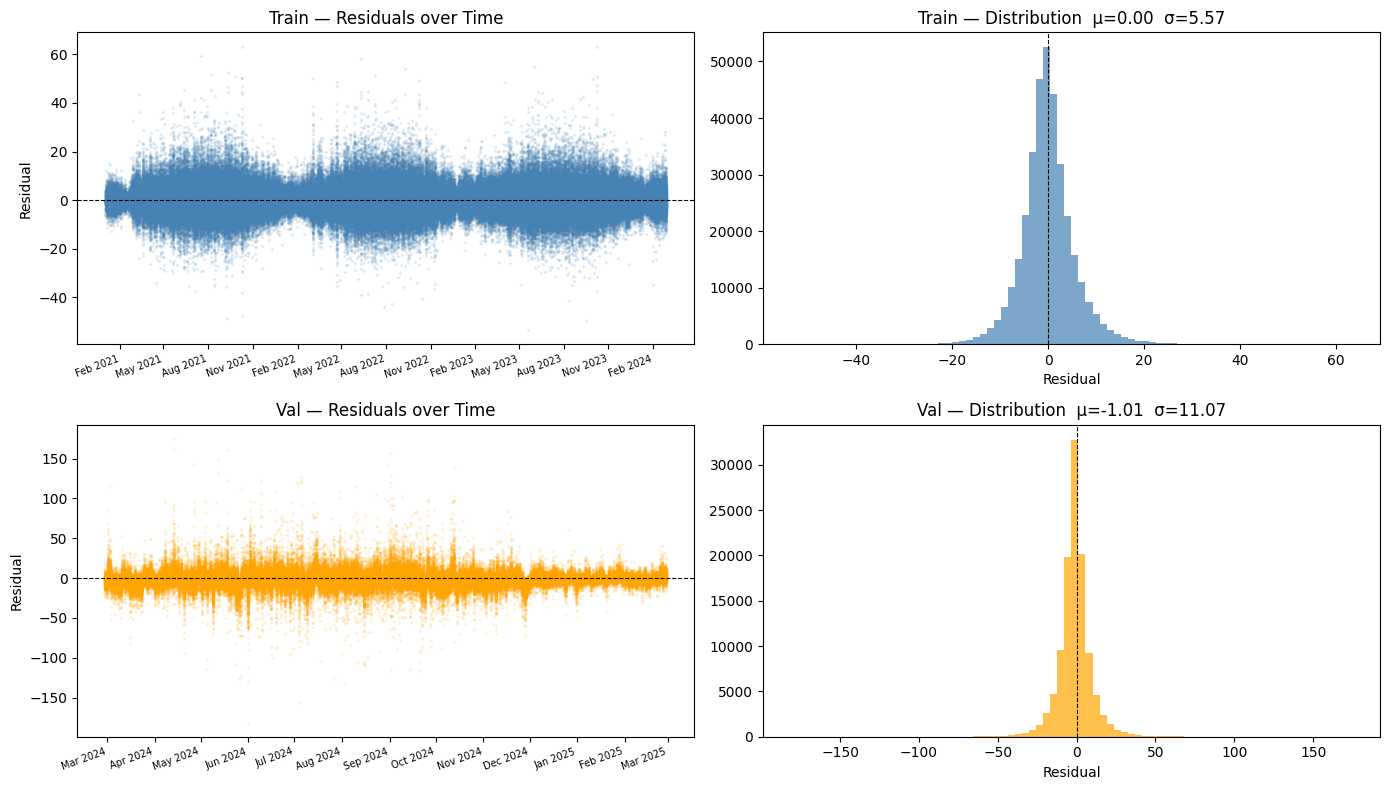

In [250]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for (data, resid_col, color, label), ax_row in zip(
    [(train_eval, 'resid', 'steelblue', 'Train'),
     (val_eval,   'resid', 'orange',    'Val')],
    axes
):
    ax_row[0].scatter(data['date'], data[resid_col], alpha=0.1, s=2, color=color)
    ax_row[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax_row[0].set_title(f'{label} — Residuals over Time')
    ax_row[0].set_ylabel('Residual')
    ax_row[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax_row[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3 if label=='Train' else 1))
    plt.setp(ax_row[0].xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)

    r = data[resid_col]
    ax_row[1].hist(r, bins=80, color=color, alpha=0.7, edgecolor='none')
    ax_row[1].axvline(0, color='black', linewidth=0.8, linestyle='--')
    ax_row[1].set_title(f'{label} — Distribution  μ={r.mean():.2f}  σ={r.std():.2f}')
    ax_row[1].set_xlabel('Residual')

plt.tight_layout()
plt.show()

## 6. Daily SSR

/var/folders/pz/n51wnxpj59g9w6k9pl_ty57w0000gn/T/ipykernel_23844/1646567544.py:19: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


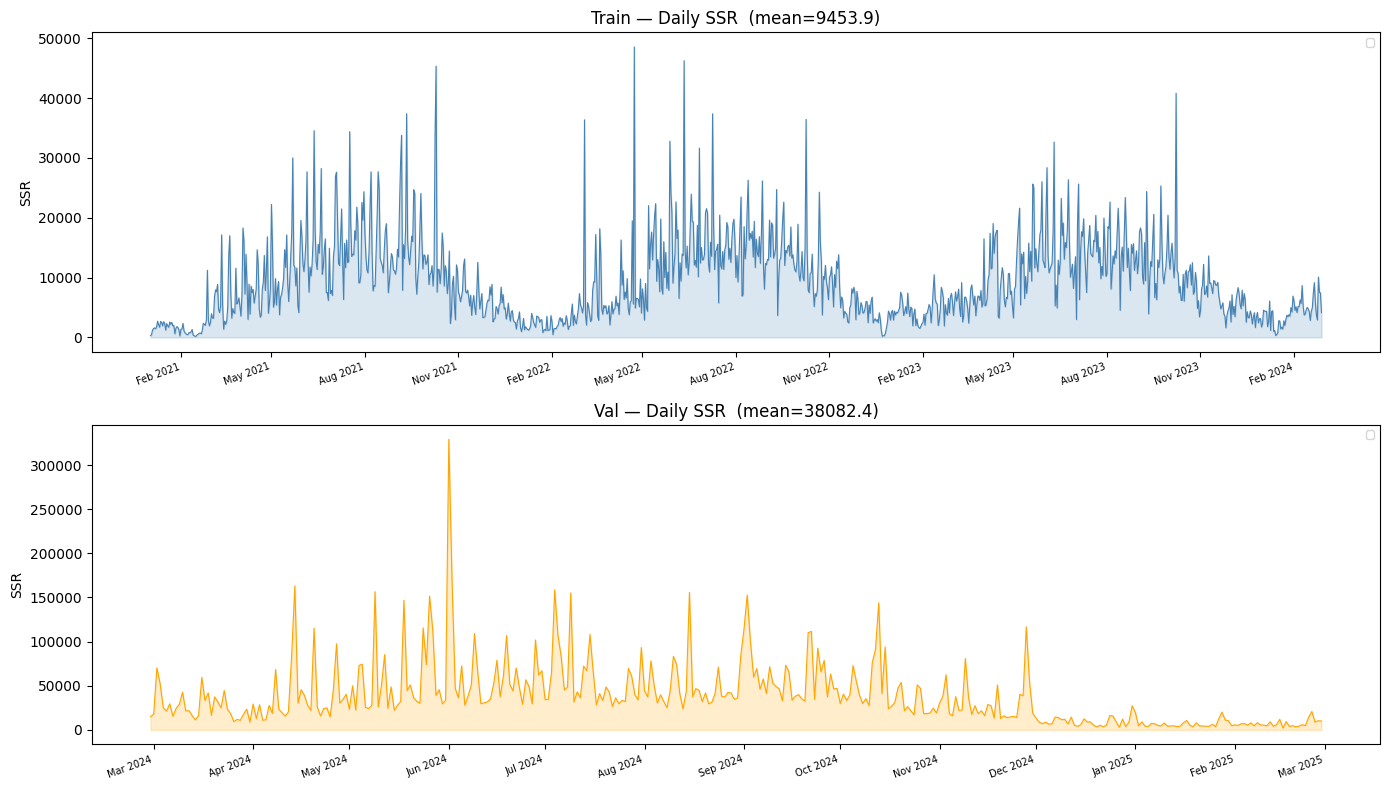

Worst train day: 2022-04-23  SSR=48562.7
Worst val day:   2024-06-01    SSR=329089.2


In [251]:
train_eval['resid2'] = train_eval['resid'] ** 2
val_eval['resid2']   = val_eval['resid'] ** 2

ssr_train = train_eval.groupby('date')['resid2'].sum()
ssr_val   = val_eval.groupby('date')['resid2'].sum()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

for ax, ssr, color, label in [
    (axes[0], ssr_train, 'steelblue', 'Train'),
    (axes[1], ssr_val,   'orange',    'Val'),
]:
    worst = ssr.idxmax()
    ax.plot(ssr.index, ssr.values, linewidth=0.8, color=color)
    ax.fill_between(ssr.index, ssr.values, alpha=0.2, color=color)
    # ax.axvline(worst, color='red', linewidth=1.2, linestyle='--', label=f'Largest spike: {worst.date()}')
    ax.set_title(f'{label} — Daily SSR  (mean={ssr.mean():.1f})')
    ax.set_ylabel('SSR')
    ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3 if label=='Train' else 1))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)

plt.tight_layout()
plt.show()

worst_train_date = ssr_train.idxmax()
worst_val_date   = ssr_val.idxmax()
print(f'Worst train day: {worst_train_date.date()}  SSR={ssr_train[worst_train_date]:.1f}')
print(f'Worst val day:   {worst_val_date.date()}    SSR={ssr_val[worst_val_date]:.1f}')


## 7. Prediction vs actual — top 5 stations

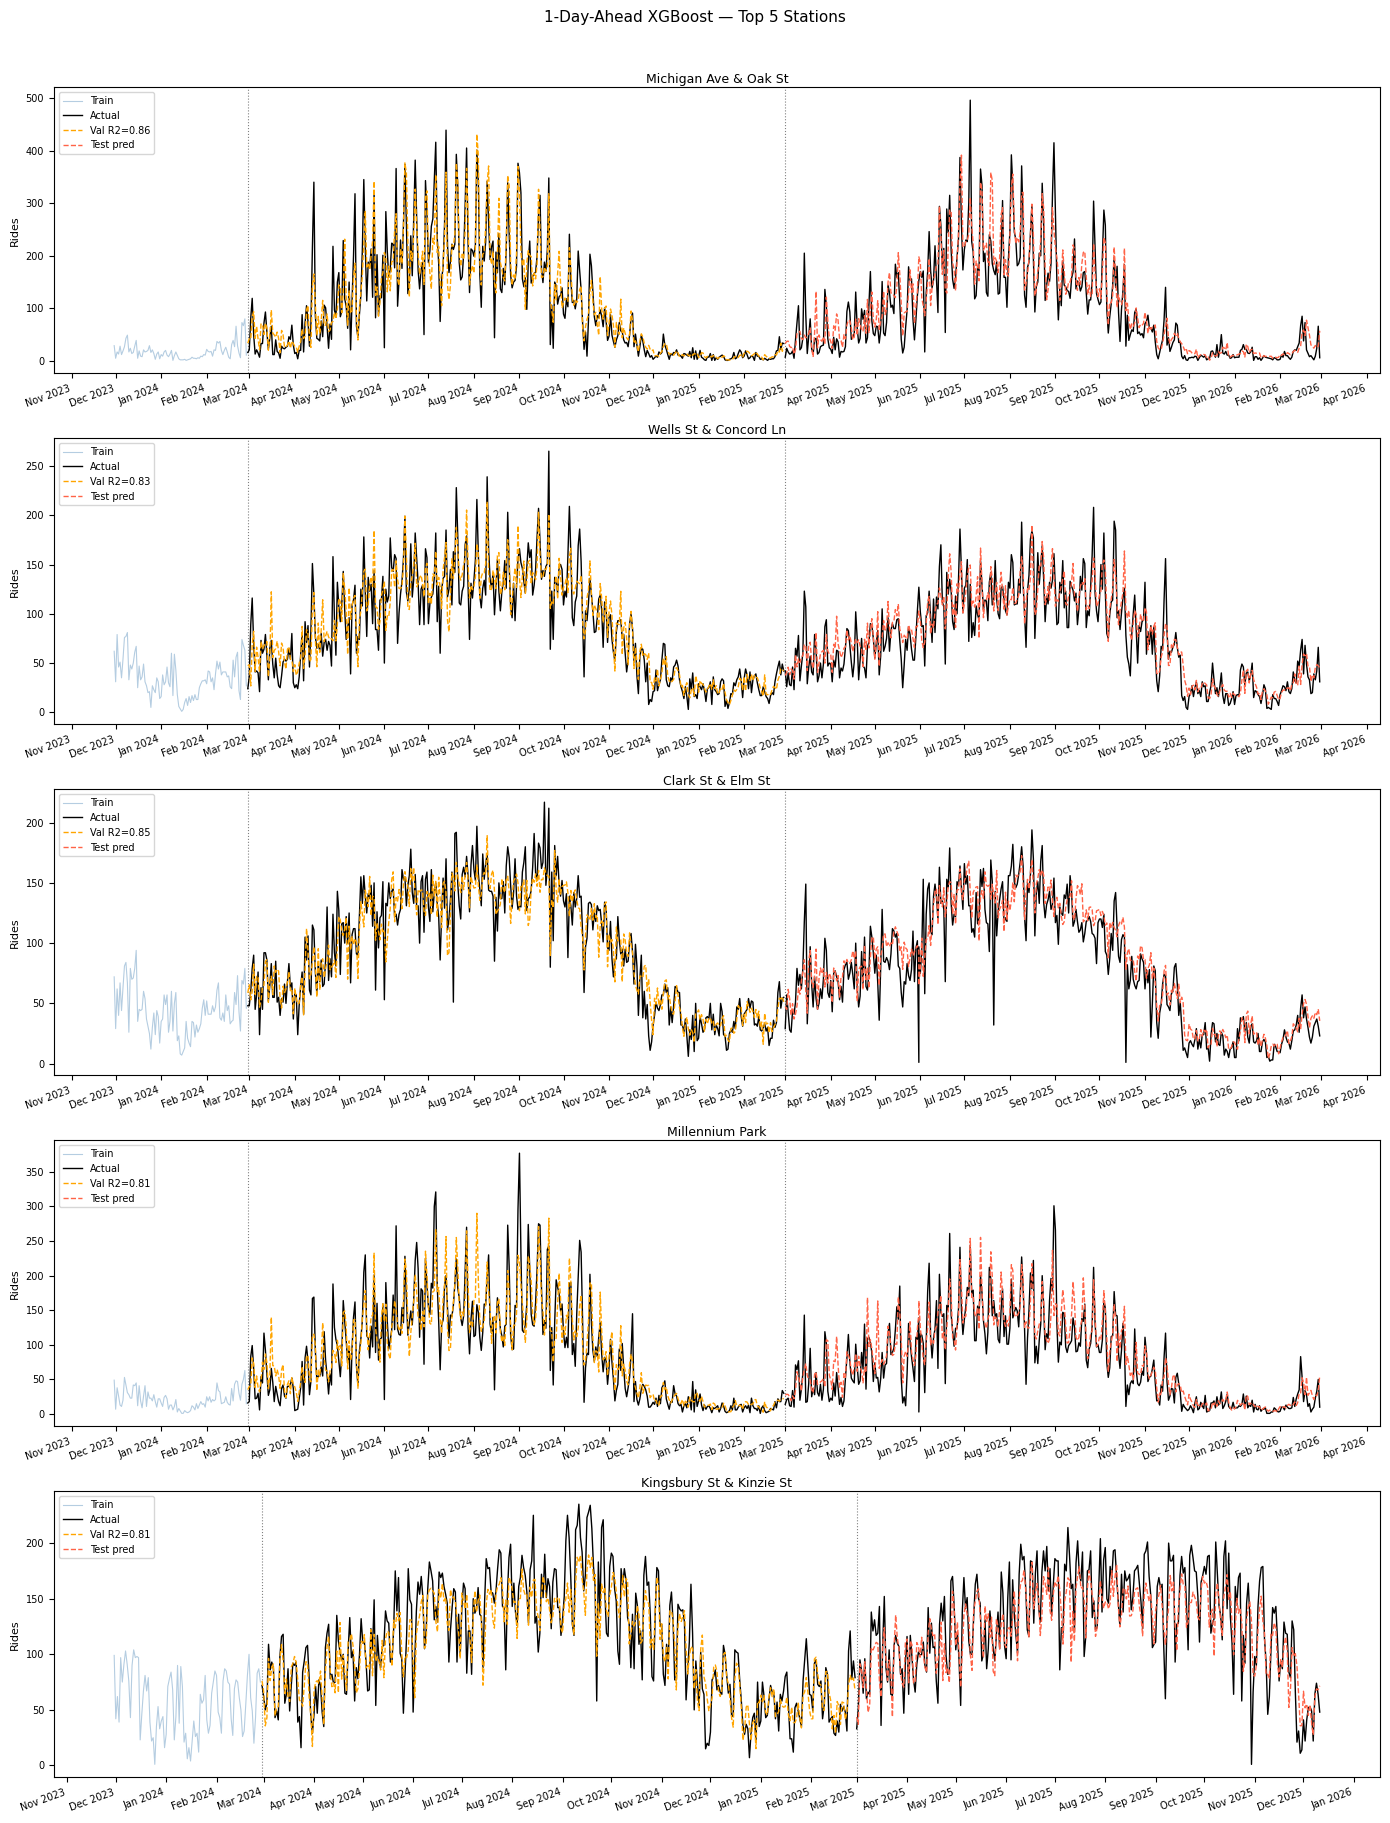

In [252]:
top5 = (
    train.groupby('start_station_name')['total_rides']
    .sum().sort_values(ascending=False).head(5).index.tolist()
)
CONTEXT_DAYS = 90

fig, axes = plt.subplots(5, 1, figsize=(14, 18), sharex=False)
for ax, name in zip(axes, top5):
    tr     = train[train['start_station_name'] == name]
    tr_ctx = tr[tr['date'] >= tr['date'].max() - pd.Timedelta(days=CONTEXT_DAYS)]
    vl     = val_eval[val_eval['start_station_name'] == name].sort_values('date')
    te     = test_eval[test_eval['start_station_name'] == name].sort_values('date')
    r2_v   = r2_score(vl['total_rides'], vl['pred'])

    ax.plot(tr_ctx['date'], tr_ctx['total_rides'], color='steelblue', alpha=0.4, linewidth=0.8, label='Train')
    ax.axvline(vl['date'].min(), color='grey', linestyle=':', linewidth=0.8)
    ax.axvline(te['date'].min(), color='grey', linestyle=':', linewidth=0.8)
    ax.plot(vl['date'], vl['total_rides'], color='black',  linewidth=1, label='Actual')
    ax.plot(vl['date'], vl['pred'],        color='orange', linestyle='--', linewidth=1, label=f'Val R2={r2_v:.2f}')
    ax.plot(te['date'], te['total_rides'], color='black',  linewidth=1)
    ax.plot(te['date'], te['pred'],        color='tomato', linestyle='--', linewidth=1, label='Test pred')
    ax.set_title(name, fontsize=9, pad=3)
    ax.set_ylabel('Rides', fontsize=8)
    ax.legend(fontsize=7, loc='upper left')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)
    ax.tick_params(axis='y', labelsize=7)

fig.suptitle('1-Day-Ahead XGBoost — Top 5 Stations', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


## 8. Error breakdown by weekday & month

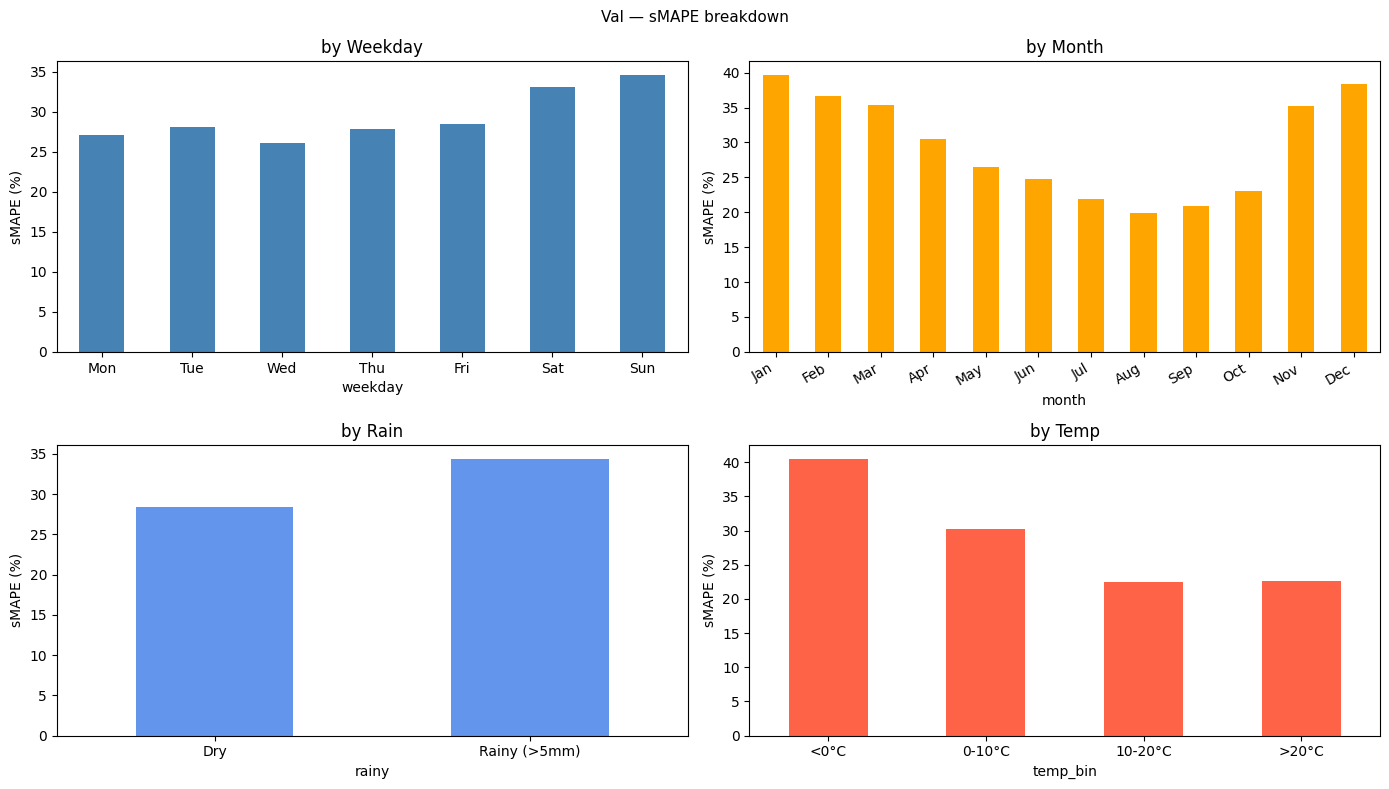

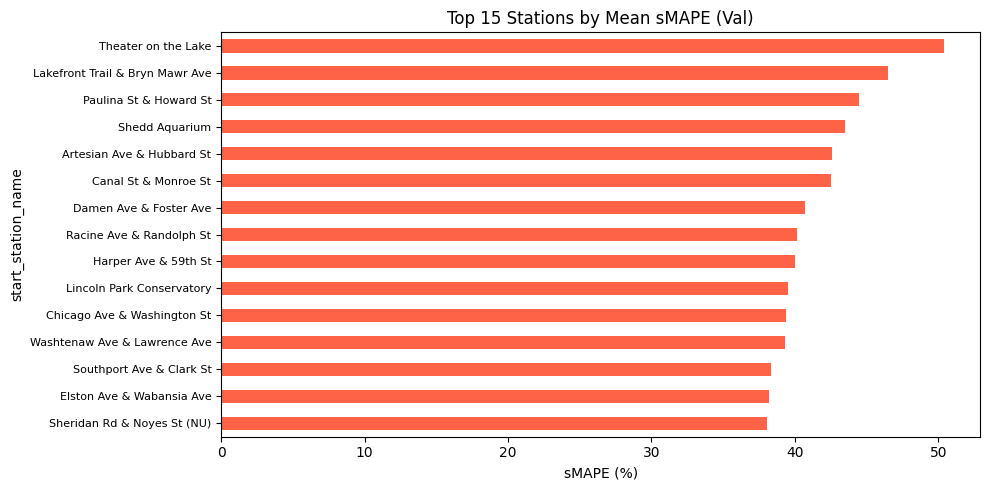

In [254]:
# sMAPE breakdown by features + top stations by sMAPE
def _smape_series(true, pred):
    return 2 * np.abs(pred - true) / (np.abs(true) + np.abs(pred))

val_eval["smape"] = _smape_series(val_eval["total_rides"], val_eval["pred"]) * 100
val_eval["weekday"] = val_eval["date"].dt.weekday
val_eval["month"]   = val_eval["date"].dt.month

# Merge rain & temp from df for weather breakdown
weather_day = df[["date","rain_sum_mm","temp_min_c"]].drop_duplicates("date")
weather_day["date"] = pd.to_datetime(weather_day["date"])
val_w = val_eval.merge(weather_day, on="date", how="left")
val_w["rainy"]   = (val_w["rain_sum_mm"] > 5).map({True: "Rainy (>5mm)", False: "Dry"})
val_w["temp_bin"] = pd.cut(val_w["temp_min_c"], bins=[-30, 0, 10, 20, 40],
                           labels=["<0°C", "0-10°C", "10-20°C", ">20°C"])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Val — sMAPE breakdown", fontsize=11)

val_eval.groupby("weekday")["smape"].mean().plot.bar(
    ax=axes[0,0], color="steelblue", edgecolor="none")
axes[0,0].set_title("by Weekday")
axes[0,0].set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], rotation=0)
axes[0,0].set_ylabel("sMAPE (%)")

val_eval.groupby("month")["smape"].mean().plot.bar(
    ax=axes[0,1], color="orange", edgecolor="none")
axes[0,1].set_title("by Month")
axes[0,1].set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=30, ha="right")
axes[0,1].set_ylabel("sMAPE (%)")

val_w.groupby("rainy")["smape"].mean().plot.bar(
    ax=axes[1,0], color="cornflowerblue", edgecolor="none")
axes[1,0].set_title("by Rain")
axes[1,0].set_ylabel("sMAPE (%)")
axes[1,0].tick_params(axis="x", rotation=0)

val_w.groupby("temp_bin", observed=True)["smape"].mean().plot.bar(
    ax=axes[1,1], color="tomato", edgecolor="none")
axes[1,1].set_title("by Temp")
axes[1,1].set_ylabel("sMAPE (%)")
axes[1,1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Top 15 stations by mean sMAPE (val)
stn_smape = (
    val_eval.groupby("start_station_name")["smape"].mean()
    .sort_values(ascending=False).head(15)
)
fig, ax = plt.subplots(figsize=(10, 5))
stn_smape.sort_values().plot.barh(ax=ax, color="tomato", edgecolor="none")
ax.set_title("Top 15 Stations by Mean sMAPE (Val)")
ax.set_xlabel("sMAPE (%)")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()


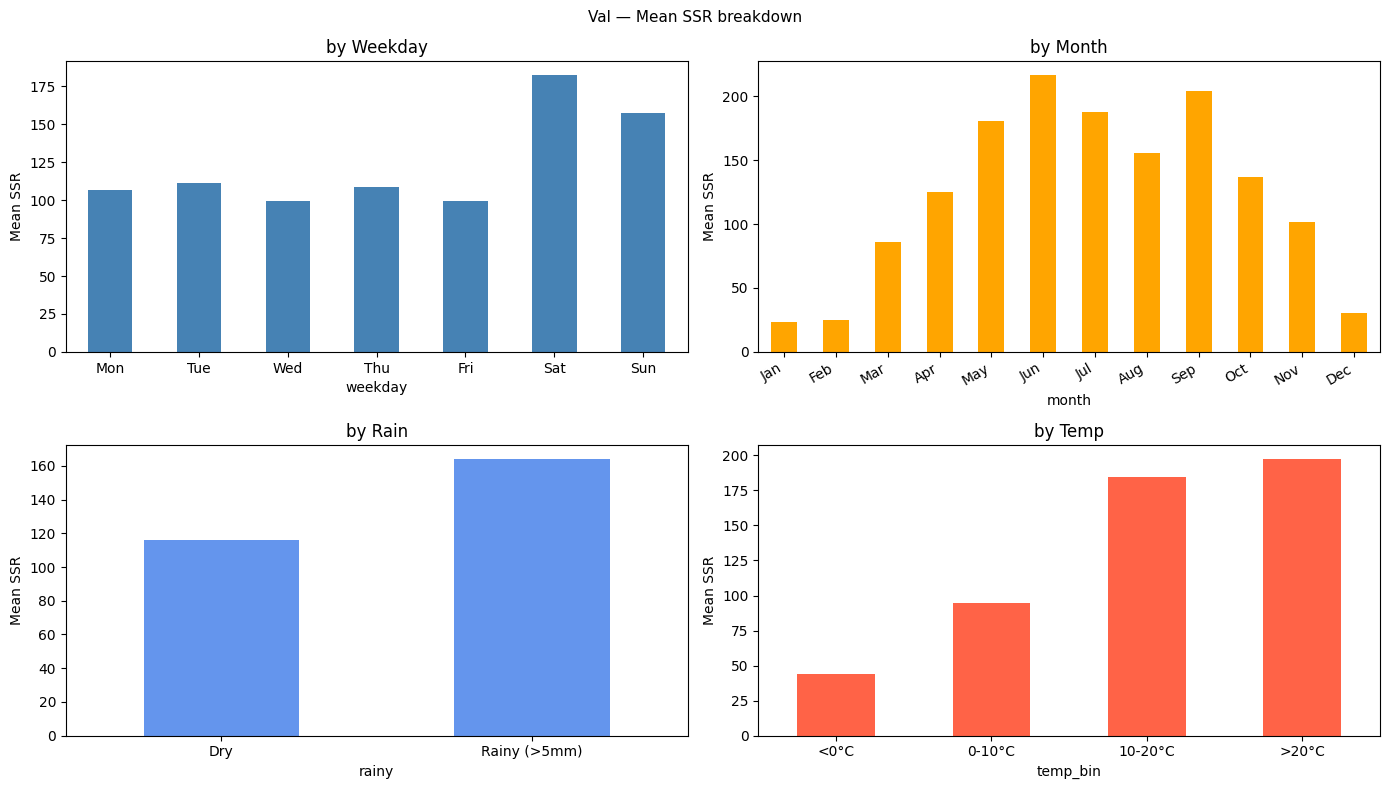

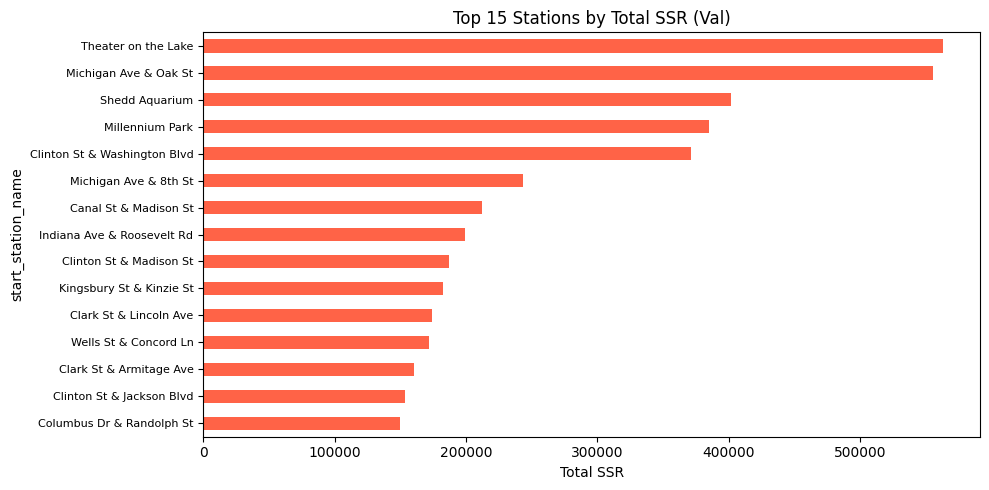

In [264]:
# SSR breakdown by features + top stations by total SSR
val_eval["resid2"] = val_eval["resid"] ** 2
val_eval["weekday"] = val_eval["date"].dt.weekday
val_eval["month"]   = val_eval["date"].dt.month

val_w2 = val_eval.merge(weather_day, on="date", how="left")
val_w2["rainy"]    = (val_w2["rain_sum_mm"] > 5).map({True: "Rainy (>5mm)", False: "Dry"})
val_w2["temp_bin"] = pd.cut(val_w2["temp_min_c"], bins=[-30, 0, 10, 20, 40],
                            labels=["<0°C", "0-10°C", "10-20°C", ">20°C"])

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Val — Mean SSR breakdown", fontsize=11)

val_eval.groupby("weekday")["resid2"].mean().plot.bar(
    ax=axes[0,0], color="steelblue", edgecolor="none")
axes[0,0].set_title("by Weekday")
axes[0,0].set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], rotation=0)
axes[0,0].set_ylabel("Mean SSR")

val_eval.groupby("month")["resid2"].mean().plot.bar(
    ax=axes[0,1], color="orange", edgecolor="none")
axes[0,1].set_title("by Month")
axes[0,1].set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=30, ha="right")
axes[0,1].set_ylabel("Mean SSR")

val_w2.groupby("rainy")["resid2"].mean().plot.bar(
    ax=axes[1,0], color="cornflowerblue", edgecolor="none")
axes[1,0].set_title("by Rain")
axes[1,0].set_ylabel("Mean SSR")
axes[1,0].tick_params(axis="x", rotation=0)

val_w2.groupby("temp_bin", observed=True)["resid2"].mean().plot.bar(
    ax=axes[1,1], color="tomato", edgecolor="none")
axes[1,1].set_title("by Temp")
axes[1,1].set_ylabel("Mean SSR")
axes[1,1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

# Top 15 stations by total SSR (val)
stn_ssr_val = (
    val_eval.groupby("start_station_name")["resid2"].sum()
    .sort_values(ascending=False).head(15)
)
fig, ax = plt.subplots(figsize=(10, 5))
stn_ssr_val.sort_values().plot.barh(ax=ax, color="tomato", edgecolor="none")
ax.set_title("Top 15 Stations by Total SSR (Val)")
ax.set_xlabel("Total SSR")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()


## 9. Largest SSR spike — drill down to raw trips

In [255]:
# --- Adjust K to explore different spike days ---
K = 1  # 1 = largest, 2 = 2nd largest, etc.

ssr_in_trip = ssr_train[ssr_train.index.isin(trip_dates)]
worst_date  = ssr_in_trip.nlargest(K).index[-1]
print(f'#{K} largest SSR day: {worst_date.date()}  (SSR={ssr_in_trip[worst_date]:.0f})')

day_resid = (
    train_eval[train_eval['date'] == worst_date]
    [['start_station_name', 'total_rides', 'pred', 'resid']]
    .assign(resid2=lambda x: (x['resid'] ** 2).round().astype(int))
    .sort_values('resid2', ascending=False)
)
print(f'Top 10 stations by squared residual on {worst_date.date()}:')
day_resid.head(10)


#1 largest SSR day: 2023-10-08  (SSR=40812)
Top 10 stations by squared residual on 2023-10-08:


,start_station_name,total_rides,pred,resid,resid2
608548,State St & Van Buren St,118,55.036278,62.963722,3964
626294,Wabash Ave & Adams St,103,52.458813,50.541187,2554
413646,Michigan Ave & 18th St,88,40.736912,47.263088,2234
418109,Michigan Ave & Ida B Wells Dr,105,60.132347,44.867653,2013
316297,Indiana Ave & 26th St,57,19.055338,37.944662,1440
320674,Indiana Ave & Roosevelt Rd,1,38.294273,-37.294273,1391
265381,Franklin St & Chicago Ave,82,48.660431,33.339569,1112
229825,Desplaines St & Jackson Blvd,86,53.985596,32.014404,1025
254202,Fairbanks Ct & Grand Ave,15,46.535236,-31.535236,994
225363,Dearborn St & Van Buren St,56,24.994495,31.005505,961


In [256]:
print(f'Loading trip data ...')
trip = s3.read_processed('trip/all')
trip['date'] = pd.to_datetime(trip['date'])
trip_dates = set(trip['date'].unique())

# Find worst day that exists in trip data
ssr_in_trip = ssr_train[ssr_train.index.isin(trip_dates)]
if ssr_in_trip.empty:
    print('No train SSR dates overlap with trip data — using val instead')
    ssr_in_trip = ssr_val[ssr_val.index.isin(trip_dates)]

worst_date = ssr_in_trip.idxmax()
print(f'Worst day with trip data: {worst_date.date()}  (SSR={ssr_in_trip[worst_date]:.1f})')

day_trips = trip[trip['date'] == worst_date].copy()
print(f'Station-route records: {len(day_trips):,}  |  Total rides: {day_trips["total_rides"].sum():,}')
day_trips.sort_values("total_rides", ascending=False).head(15)


Loading trip data ...
Worst day with trip data: 2023-10-08  (SSR=40811.5)
Station-route records: 9,713  |  Total rides: 15,402


,date,start_station_name,start_station_id,end_station_name,end_station_id,total_rides,member_rides,casual_rides
2436636,2023-10-08,Streeter Dr & Grand Ave,13022,Streeter Dr & Grand Ave,13022,41,3,38
2431572,2023-10-08,Ellis Ave & 60th St,KA1503000014,University Ave & 57th St,KA1503000071,40,28,12
2436733,2023-10-08,University Ave & 57th St,KA1503000071,Ellis Ave & 60th St,KA1503000014,38,24,14
2431561,2023-10-08,Ellis Ave & 60th St,KA1503000014,Ellis Ave & 55th St,KA1504000076,34,20,14
2431317,2023-10-08,DuSable Lake Shore Dr & Monroe St,13300,DuSable Lake Shore Dr & Monroe St,13300,31,5,26
2431536,2023-10-08,Ellis Ave & 55th St,KA1504000076,Ellis Ave & 60th St,KA1503000014,27,19,8
2431352,2023-10-08,DuSable Lake Shore Dr & Monroe St,13300,Streeter Dr & Grand Ave,13022,22,2,20
2435495,2023-10-08,Shedd Aquarium,15544,Streeter Dr & Grand Ave,13022,17,2,15
2432129,2023-10-08,Halsted St & 18th St,13099,Michigan Ave & 18th St,13150,17,2,15
2436723,2023-10-08,University Ave & 57th St,KA1503000071,Blackstone Ave & 59th St,22004,17,12,5


## 10. Stations with Largest Total SSR

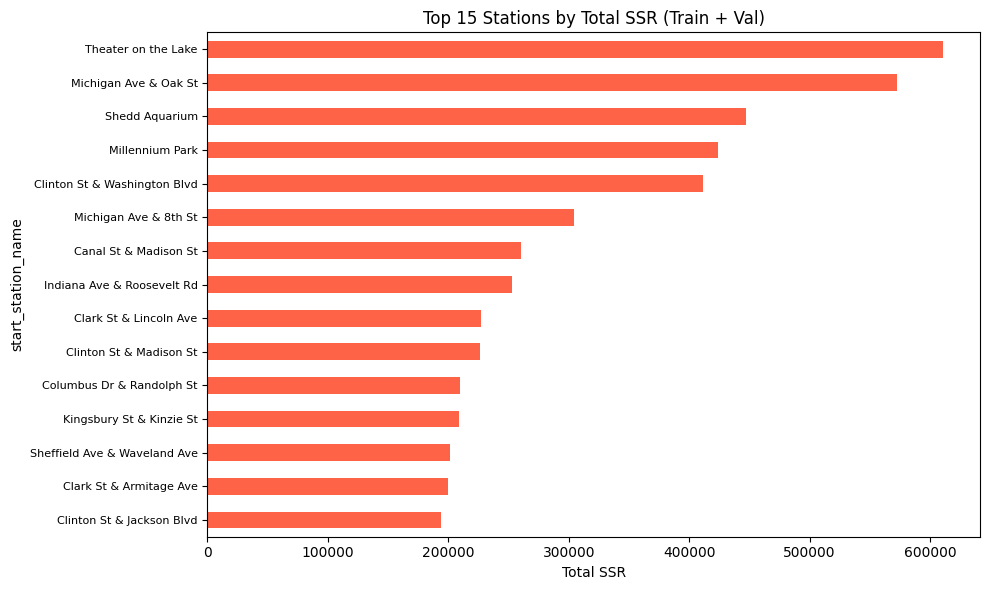

,start_station_name,total_ssr
0,Theater on the Lake,610951
1,Michigan Ave & Oak St,572430
2,Shedd Aquarium,447163
3,Millennium Park,423993
4,Clinton St & Washington Blvd,411344
5,Michigan Ave & 8th St,304357
6,Canal St & Madison St,260448
7,Indiana Ave & Roosevelt Rd,253273
8,Clark St & Lincoln Ave,226920
9,Clinton St & Madison St,225931


In [259]:
# Total SSR per station (train + val)
stn_ssr = (
    pd.concat([train_eval, val_eval])
    .groupby('start_station_name')['resid2']
    .sum()
    .round().astype(int)
    .sort_values(ascending=False)
)

TOP_N = 15
fig, ax = plt.subplots(figsize=(10, 6))
stn_ssr.head(TOP_N).sort_values().plot.barh(ax=ax, color='tomato', edgecolor='none')
ax.set_title(f'Top {TOP_N} Stations by Total SSR (Train + Val)')
ax.set_xlabel('Total SSR')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

stn_ssr.head(TOP_N).reset_index().rename(columns={'resid2': 'total_ssr'})


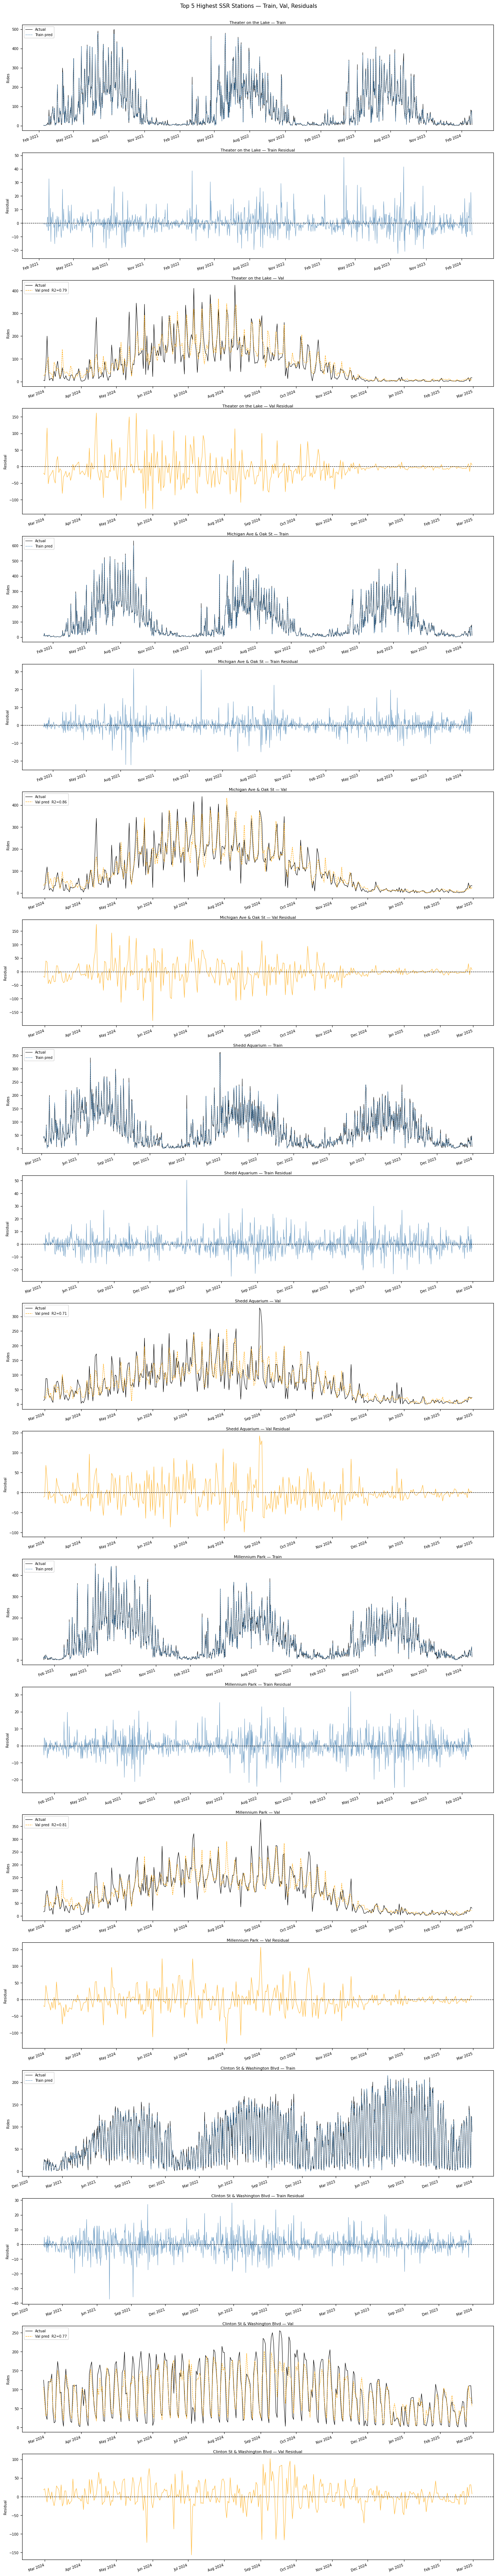

In [260]:
top5_worst = stn_ssr.head(5).index.tolist()

fig, axes = plt.subplots(20, 1, figsize=(14, 72))
fig.suptitle('Top 5 Highest SSR Stations — Train, Val, Residuals', fontsize=11, y=1.0005)

for i, name in enumerate(top5_worst):
    tr    = train_eval[train_eval['start_station_name'] == name].sort_values('date')
    vl    = val_eval[val_eval['start_station_name'] == name].sort_values('date')
    r2_v  = r2_score(vl['total_rides'], vl['pred'])
    short = name[:45] + ('...' if len(name) > 45 else '')
    base  = i * 4

    ax = axes[base]
    ax.plot(tr['date'], tr['total_rides'], color='black',     linewidth=0.7, label='Actual')
    ax.plot(tr['date'], tr['pred'],        color='steelblue', linestyle='--', linewidth=0.7, label='Train pred')
    ax.set_title(f'{short} — Train', fontsize=8, pad=2)
    ax.set_ylabel('Rides', fontsize=7)
    ax.legend(fontsize=7, loc='upper left')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)
    ax.tick_params(axis='y', labelsize=7)

    ax = axes[base + 1]
    ax.plot(tr['date'], tr['resid'], color='steelblue', linewidth=0.7, alpha=0.8)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'{short} — Train Residual', fontsize=8, pad=2)
    ax.set_ylabel('Residual', fontsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)
    ax.tick_params(axis='y', labelsize=7)

    ax = axes[base + 2]
    ax.plot(vl['date'], vl['total_rides'], color='black',  linewidth=0.8, label='Actual')
    ax.plot(vl['date'], vl['pred'],        color='orange', linestyle='--', linewidth=0.8, label=f'Val pred  R2={r2_v:.2f}')
    ax.set_title(f'{short} — Val', fontsize=8, pad=2)
    ax.set_ylabel('Rides', fontsize=7)
    ax.legend(fontsize=7, loc='upper left')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)
    ax.tick_params(axis='y', labelsize=7)

    ax = axes[base + 3]
    ax.plot(vl['date'], vl['resid'], color='orange', linewidth=0.8, alpha=0.8)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'{short} — Val Residual', fontsize=8, pad=2)
    ax.set_ylabel('Residual', fontsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=20, ha='right', fontsize=7)
    ax.tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.show()
